# Project 5 — Strategic asset allocation for the Northbridge University Endowment
Fictional client (fixed profile): $2.0bn, perpetual horizon, spending 4.5% of the trailing
12-quarter average market value, costs 0.40%/yr, objective inflation + 4.9% net, risk limit
volatility <= 12% and <= 5% probability of a one-year loss worse than -20%.
Capital market assumptions: J.P. Morgan Asset Management, 2026 Long-Term Capital Market
Assumptions (30th edition, data as of 30 September 2025), U.S. dollar matrix.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT.parent)]

import numpy as np
import pandas as pd

from common import data as D
from common.plotting import PALETTE, setup, source
from src import ltcma, saa

plt = setup()
DATA, FIG = ROOT / "data", ROOT / "report" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.options.display.float_format = "{:.4f}".format
SRC_JPM = "Source: J.P. Morgan Asset Management, 2026 LTCMA (USD); author's calculations."

## Capital market assumptions mapped to the 11 ETFs

In [2]:
A, CORR = ltcma.load(DATA)
etf = A[A["ETF"].notna()].set_index("ETF")
TICK = list(etf.index)
mu = etf["Arithmetic 2026"]
geo = etf["Compound 2026"]
vol = etf["Volatility"]
C = CORR.loc[list(ltcma.MAP.values()), list(ltcma.MAP.values())].values
S = pd.DataFrame(np.outer(vol, vol) * C, TICK, TICK)
infl = A.loc["U.S. Inflation"]
print("Inflation assumption (compound):", infl["Compound 2026"])
etf.assign(Class=[k for k in ltcma.MAP.values()])

Inflation assumption (compound): 0.025


,Compound 2026,Arithmetic 2026,Volatility,Compound 2025,Class
ETF,,,,,
SPY,0.0670,0.0794,0.1647,0.0670,U.S. Large Cap
EFA,0.0750,0.0890,0.1763,0.0810,EAFE Equity
EEM,0.0780,0.0974,0.2093,0.0720,Emerging Markets Equity
IEF,0.0400,0.0406,0.0348,0.0380,U.S. Intermediate Treasuries
TLT,0.0490,0.0569,0.1302,0.0430,U.S. Long Treasuries
TIP,0.0430,0.0447,0.0588,0.0410,TIPS
LQD,0.0520,0.0546,0.0739,0.0500,U.S. Inv Grade Corporate Bonds
HYG,0.0610,0.0646,0.0874,0.0610,U.S. High Yield Bonds
VNQ,0.0880,0.1015,0.1740,0.0800,U.S. REITs


## 1. Efficient frontier under the IPS constraints

In [3]:
front = saa.frontier_curve(mu, S, n=40)
w_min = saa.frontier_portfolio(mu, S, min_vol=True)
w_max = saa.max_return_portfolio(mu)

## 2. Three candidates on the frontier

In [4]:
CAND = {"Conservative": 0.08, "Balanced": 0.10, "Growth": 0.12}
W = pd.DataFrame({k: saa.frontier_portfolio(mu, S, v) for k, v in CAND.items()}).reindex(TICK).fillna(0)


def port_stats(w):
    m, v = float(w @ mu), float(np.sqrt(w @ S @ w))
    return {"Expected return (arith.)": m, "Expected return (compound, approx.)": m - v ** 2 / 2,
            "Volatility": v, "Equities": w[saa.EQ].sum(), "Treasuries + TIPS": w[saa.GOVT].sum(),
            "Gold + commodities": w[saa.REAL].sum(), "Credit (LQD, HYG)": w[["LQD", "HYG"]].sum()}


P = pd.DataFrame({k: port_stats(W[k]) for k in W}).T
W.round(3), P

(     Conservative  Balanced  Growth
 SPY        0.0000    0.0000  0.0000
 EFA        0.0610    0.0000  0.0000
 EEM        0.0480    0.0590  0.1990
 IEF        0.4000    0.0560  0.0000
 TLT        0.0260    0.1310  0.1500
 TIP        0.0000    0.0000  0.0000
 LQD        0.0000    0.0000  0.0000
 HYG        0.0740    0.3010  0.1510
 VNQ        0.2900    0.3530  0.4000
 GLD        0.1000    0.1000  0.1000
 DBC        0.0000    0.0000  0.0000,
               Expected return (arith.)  Expected return (compound, approx.)  \
 Conservative                    0.0689                               0.0657   
 Balanced                        0.0775                               0.0725   
 Growth                          0.0851                               0.0779   
 
               Volatility  Equities  Treasuries + TIPS  Gold + commodities  \
 Conservative      0.0800    0.4000             0.4264              0.1000   
 Balanced          0.1000    0.4122             0.1869              0.1000   

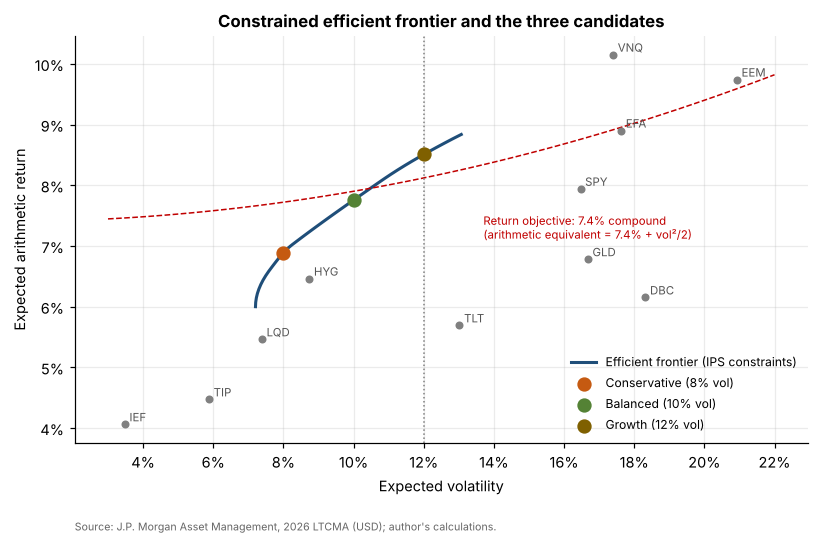

In [5]:
fig, ax = plt.subplots(figsize=(8.6, 4.8))
ax.plot(front["vol"], front["ret"], color=PALETTE[0], lw=2, label="Efficient frontier (IPS constraints)")
ax.scatter(vol, mu, color="grey", s=18, zorder=3)
for t in TICK:
    ax.annotate(t, (vol[t], mu[t]), fontsize=7.5, xytext=(3, 2), textcoords="offset points", color="#555555")
for i, (k, v) in enumerate(CAND.items()):
    ax.scatter(P.loc[k, "Volatility"], P.loc[k, "Expected return (arith.)"], s=70, zorder=4,
               color=PALETTE[i + 1], label=f"{k} ({v:.0%} vol)")
hurdle = infl["Compound 2026"] + 0.049
vv = np.linspace(0.03, 0.22, 50)
ax.plot(vv, hurdle + vv ** 2 / 2, color="#C00000", ls="--", lw=1)   # arithmetic return needed for a 7.4% compound return
ax.annotate(f"Return objective: {hurdle:.1%} compound\n(arithmetic equivalent = {hurdle:.1%} + vol²/2)", (0.137, 0.0712),
            fontsize=7.5, color="#C00000")
ax.axvline(0.12, color="grey", ls=":", lw=1)
ax.set_xlabel("Expected volatility"); ax.set_ylabel("Expected arithmetic return")
ax.xaxis.set_major_locator(plt.MultipleLocator(0.02))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set_title("Constrained efficient frontier and the three candidates")
ax.legend(fontsize=8, loc="lower right")
source(ax, SRC_JPM)
fig.savefig(FIG / "fig_frontier.png"); plt.show()

## Sensitivity: how much does the answer depend on the REIT assumption?
Re-optimize the 12%-volatility portfolio with the REIT (VNQ) expected return lowered by 1 and 2
percentage points, all else equal.

In [6]:
sens = {}
for cut in [0.0, 0.01, 0.02]:
    mu_s = mu.copy(); mu_s["VNQ"] -= cut
    sens[f"VNQ -{cut:.0%}"] = saa.frontier_portfolio(mu_s, S, 0.12)
SENS = pd.DataFrame(sens).reindex(TICK).fillna(0)
SENS.round(3)

,VNQ -0%,VNQ -1%,VNQ -2%
SPY,0.0000,0.0000,0.0000
EFA,0.0000,0.0200,0.2380
EEM,0.1990,0.2210,0.2470
IEF,0.0000,0.0000,0.0000
TLT,0.1500,0.1520,0.2000
TIP,0.0000,0.0000,0.0000
LQD,0.0000,0.0000,0.0000
HYG,0.1510,0.1490,0.1260
VNQ,0.4000,0.3580,0.0890
GLD,0.1000,0.1000,0.1000


## 3. Monte Carlo: 10,000 paths x 20 years (quarterly steps)

In [7]:
arith_all = pd.concat([mu, pd.Series({"INFL": infl["Arithmetic 2026"]})])
vol_all = pd.concat([vol, pd.Series({"INFL": infl["Volatility"]})])
names = list(ltcma.MAP.values()) + ["U.S. Inflation"]
corr_all = CORR.loc[names, names].copy()
corr_all.index = corr_all.columns = TICK + ["INFL"]
MC, SPEND, SIMS = {}, {}, {}
for k in W:
    sim = saa.simulate(W[k], arith_all, vol_all, corr_all, years=20, paths=10_000, seed=2026)
    MC[k], SPEND[k] = saa.mc_summary(sim)
    SIMS[k] = sim
MC = pd.DataFrame(MC).T
MC

,"P(real value preserved, 20y)",Median real value after 20y ($bn),P(drawdown worse than -30%),Median max drawdown,P(1-year loss worse than -20%),"P(1-year loss worse than -20%), year 1",Median annual net return,Median real spending yr 1 ($m),Median real spending yr 20 ($m)
Conservative,0.3161,1.6804,0.2186,-0.2205,0.0000,0.0000,0.0611,88.7091,73.9240
Balanced,0.4725,1.9384,0.3438,-0.2576,0.0008,0.0004,0.0683,88.7378,83.8646
Growth,0.5550,2.1524,0.4824,-0.2956,0.0034,0.0022,0.0739,88.7625,92.7177


## 4. Selection rule: highest probability of preserving real value among candidates meeting the risk limit

In [8]:
P["Meets vol limit (<=12%)"] = P["Volatility"] <= 0.12 + 1e-6
P["Meets loss limit (P<=5%)"] = MC["P(1-year loss worse than -20%)"] <= 0.05
eligible = P.index[P["Meets vol limit (<=12%)"] & P["Meets loss limit (P<=5%)"]]
CHOSEN = MC.loc[eligible, "P(real value preserved, 20y)"].idxmax()
print("Eligible:", list(eligible), "-> chosen:", CHOSEN)
pd.concat([P, MC], axis=1).T

Eligible: ['Conservative', 'Balanced', 'Growth'] -> chosen: Growth


,Conservative,Balanced,Growth
Expected return (arith.),0.0689,0.0775,0.0851
"Expected return (compound, approx.)",0.0657,0.0725,0.0779
Volatility,0.0800,0.1000,0.1200
Equities,0.4000,0.4122,0.5994
Treasuries + TIPS,0.4264,0.1869,0.1500
Gold + commodities,0.1000,0.1000,0.1000
"Credit (LQD, HYG)",0.0736,0.3009,0.1506
Meets vol limit (<=12%),True,True,True
Meets loss limit (P<=5%),True,True,True
"P(real value preserved, 20y)",0.3161,0.4725,0.5550


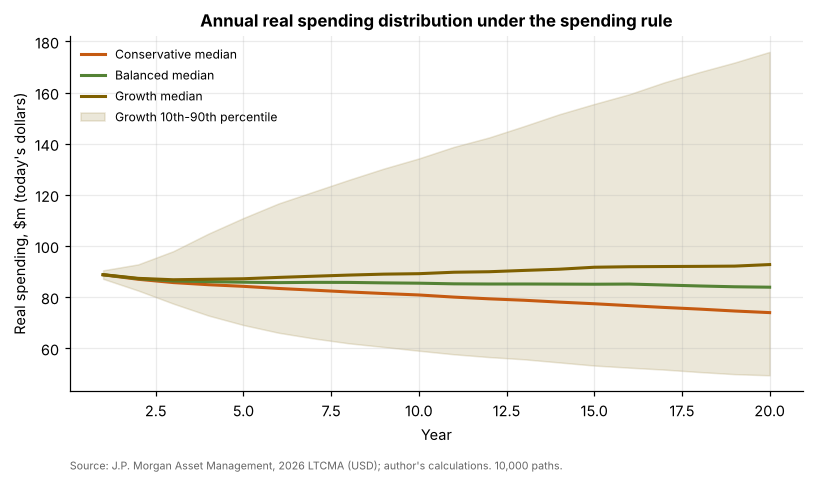

In [9]:
fig, ax = plt.subplots(figsize=(8.6, 4.2))
yrs = np.arange(1, 21)
for i, k in enumerate(W):
    rs = SPEND[k] / 1e6
    ax.plot(yrs, np.median(rs, axis=0), lw=2, color=PALETTE[i + 1], label=f"{k} median")
    if k == CHOSEN:
        ax.fill_between(yrs, np.percentile(rs, 10, axis=0), np.percentile(rs, 90, axis=0),
                        color=PALETTE[i + 1], alpha=0.15, label=f"{k} 10th-90th percentile")
ax.set_xlabel("Year"); ax.set_ylabel("Real spending, $m (today's dollars)")
ax.set_title("Annual real spending distribution under the spending rule")
ax.legend(fontsize=8)
source(ax, SRC_JPM + " 10,000 paths.")
fig.savefig(FIG / "fig_real_spending.png"); plt.show()

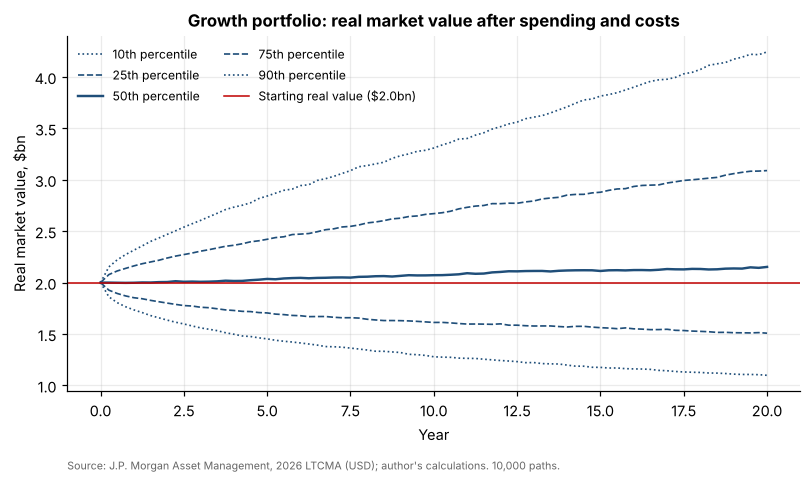

In [10]:
fig, ax = plt.subplots(figsize=(8.6, 4.2))
sim = SIMS[CHOSEN]
real = sim["V"] / sim["cpi"] / 1e9
qy = np.arange(real.shape[1]) / 4
for p, ls in [(10, ":"), (25, "--"), (50, "-"), (75, "--"), (90, ":")]:
    ax.plot(qy, np.percentile(real, p, axis=0), ls=ls, color=PALETTE[0], lw=1.6 if p == 50 else 1.1,
            label=f"{p}th percentile")
ax.axhline(2.0, color="#C00000", lw=1, label="Starting real value ($2.0bn)")
ax.set_xlabel("Year"); ax.set_ylabel("Real market value, $bn")
ax.set_title(f"{CHOSEN} portfolio: real market value after spending and costs")
ax.legend(fontsize=8, ncol=2)
source(ax, SRC_JPM + " 10,000 paths.")
fig.savefig(FIG / "fig_real_value_fan.png"); plt.show()

## Policy weights in whole percentages
The chosen frontier portfolio is rounded to whole percentages for the IPS. Each non-integer weight
is rounded down or up; among combinations that sum to 100% and meet every IPS limit (including
volatility <= 12%), the one with the highest expected return is adopted. Its Monte Carlo is re-run.

In [11]:
import itertools

raw = W[CHOSEN] * 100
fl = np.floor(raw + 1e-9)
frac = [t for t in TICK if raw[t] - fl[t] > 1e-6]
best = None
for ups in itertools.product([0, 1], repeat=len(frac)):
    cand = fl.copy()
    for t, u in zip(frac, ups):
        cand[t] += u
    if abs(cand.sum() - 100) > 1e-9:
        continue
    wc = cand / 100
    v = float(np.sqrt(wc @ S @ wc))
    ok = (v <= 0.12 and (wc <= 0.40 + 1e-9).all() and 0.40 <= wc[saa.EQ].sum() <= 0.70
          and wc[saa.GOVT].sum() >= 0.15 - 1e-9 and wc[saa.REAL].sum() <= 0.10 + 1e-9)
    if ok and (best is None or float(wc @ mu) > float(best @ mu)):
        best = wc
POLICY = best
pol_stats = port_stats(POLICY)
sim_pol = saa.simulate(POLICY, arith_all, vol_all, corr_all, years=20, paths=10_000, seed=2026)
pol_mc, pol_spend = saa.mc_summary(sim_pol)
pd.DataFrame({"Optimizer": W[CHOSEN], "Policy (rounded)": POLICY}).round(4), {**pol_stats, **pol_mc}

(     Optimizer  Policy (rounded)
 SPY     0.0000            0.0000
 EFA     0.0000            0.0000
 EEM     0.1994            0.1900
 IEF     0.0000            0.0000
 TLT     0.1500            0.1500
 TIP     0.0000            0.0000
 LQD     0.0000            0.0000
 HYG     0.1506            0.1600
 VNQ     0.4000            0.4000
 GLD     0.1000            0.1000
 DBC     0.0000            0.0000,
 {'Expected return (arith.)': 0.084757,
  'Expected return (compound, approx.)': 0.07766999671554001,
  'Volatility': 0.11905463690642207,
  'Equities': np.float64(0.5900000000000001),
  'Treasuries + TIPS': np.float64(0.15),
  'Gold + commodities': np.float64(0.1),
  'Credit (LQD, HYG)': np.float64(0.16),
  'P(real value preserved, 20y)': 0.5524,
  'Median real value after 20y ($bn)': 2.144963154909819,
  'P(drawdown worse than -30%)': 0.4752,
  'Median max drawdown': -0.293667818414531,
  'P(1-year loss worse than -20%)': 0.003175,
  'P(1-year loss worse than -20%), year 1': 0.0022,

## 5. Rebalancing policy: +/-20% relative bands checked at each month-end
Historical cross-check of the chosen allocation using actual ETF returns since May 2007.

In [12]:
px = D.prices(D.ETFS, "2007-04-01", "2026-10-01", DATA / "etf_prices_daily.csv")
R = D.monthly_returns(px).loc["2007-05":"2026-09"][TICK]
rf = D.tbill_monthly(DATA / "fred_TB3MS.csv")
w_t = POLICY
bands = pd.DataFrame({"Target": w_t, "Lower band": w_t * 0.8, "Upper band": w_t * 1.2})


def hard_limit_breach(w, tol=0.0):
    return bool((w > 0.40 + tol).any() or w[saa.EQ].sum() < 0.40 - tol or w[saa.EQ].sum() > 0.70 + tol
                or w[saa.GOVT].sum() < 0.15 - tol or w[saa.REAL].sum() > 0.10 + tol)


def band_backtest(R, w_t, band=0.20, hard_limits=False, tol=0.0):
    """Month-end check; on a breach the whole portfolio is rebalanced to target."""
    w = w_t.copy(); events = []; rets = []
    for t, r in R.iterrows():
        gross = float(w @ r); rets.append(gross)
        w = w * (1 + r) / (1 + gross)
        held = w_t > 0
        breach = ((w[held] < w_t[held] * (1 - band)) | (w[held] > w_t[held] * (1 + band))).any()
        if hard_limits:
            breach = breach or hard_limit_breach(w, tol)
        if breach:
            events.append(t); w = w_t.copy()
    return pd.Series(rets, R.index), events


hist_ret, events = band_backtest(R, w_t)
_, events_hard = band_backtest(R, w_t, hard_limits=True)
_, events_hard_tol = band_backtest(R, w_t, hard_limits=True, tol=0.01)
print(f"{R.index[0]:%b %Y}-{R.index[-1]:%b %Y}, {len(R)} month-ends. Rebalances triggered by: "
      f"bands only {len(events)}; bands or hard limits {len(events_hard)}; "
      f"bands or hard limits with 1-point tolerance {len(events_hard_tol)}")
bands

May 2007-Sep 2026, 233 month-ends. Rebalances triggered by: bands only 23; bands or hard limits 217; bands or hard limits with 1-point tolerance 73


,Target,Lower band,Upper band
SPY,0.0000,0.0000,0.0000
EFA,0.0000,0.0000,0.0000
EEM,0.1900,0.1520,0.2280
IEF,0.0000,0.0000,0.0000
TLT,0.1500,0.1200,0.1800
TIP,0.0000,0.0000,0.0000
LQD,0.0000,0.0000,0.0000
HYG,0.1600,0.1280,0.1920
VNQ,0.4000,0.3200,0.4800
GLD,0.1000,0.0800,0.1200


In [13]:
# Historical moments vs. LTCMA assumptions
hist = pd.DataFrame({"Hist. ann. return (arith.)": R.mean() * 12, "LTCMA arith.": mu,
                     "Hist. volatility": R.std() * np.sqrt(12), "LTCMA volatility": vol})
hc = R.corr()
corr_cmp = pd.DataFrame({"Historical": [hc.loc["SPY", "IEF"], hc.loc["SPY", "TLT"], hc.loc["SPY", "HYG"], hc.loc["SPY", "VNQ"],
                                        hc.loc["SPY", "GLD"]],
                         "LTCMA": [S.loc["SPY", "IEF"] / vol["SPY"] / vol["IEF"], S.loc["SPY", "TLT"] / vol["SPY"] / vol["TLT"],
                                   S.loc["SPY", "HYG"] / vol["SPY"] / vol["HYG"], S.loc["SPY", "VNQ"] / vol["SPY"] / vol["VNQ"],
                                   S.loc["SPY", "GLD"] / vol["SPY"] / vol["GLD"]]},
                        index=["SPY-IEF", "SPY-TLT", "SPY-HYG", "SPY-VNQ", "SPY-GLD"])
hs = {"Ann. return": (1 + hist_ret).prod() ** (12 / len(hist_ret)) - 1, "Volatility": hist_ret.std() * np.sqrt(12),
      "Worst 12-month return": ((1 + hist_ret).rolling(12).apply(np.prod, raw=True) - 1).min(),
      "Max drawdown": float(((1 + hist_ret).cumprod() / (1 + hist_ret).cumprod().cummax() - 1).min())}
r12 = (1 + hist_ret).rolling(12).apply(np.prod, raw=True) - 1
hs["Worst 12-month return ends"] = str(r12.idxmin().date())
hs["Max drawdown trough"] = str(((1 + hist_ret).cumprod() / (1 + hist_ret).cumprod().cummax() - 1).idxmin().date())
hs["Worst 12-month return 2022-23"] = float(r12.loc["2022":"2023"].min())
hs["Months with trailing 12m < -20%"] = int((r12 < -0.20).sum())
hist, corr_cmp, hs

(     Hist. ann. return (arith.)  LTCMA arith.  Hist. volatility  \
 SPY                      0.1151        0.0794            0.1547   
 EFA                      0.0593        0.0890            0.1735   
 EEM                      0.0691        0.0974            0.2103   
 IEF                      0.0313        0.0406            0.0671   
 TLT                      0.0342        0.0569            0.1411   
 TIP                      0.0330        0.0447            0.0580   
 LQD                      0.0401        0.0546            0.0825   
 HYG                      0.0512        0.0646            0.1019   
 VNQ                      0.0737        0.1015            0.2220   
 GLD                      0.1051        0.0678            0.1760   
 DBC                      0.0414        0.0615            0.1911   
 
      LTCMA volatility  
 SPY            0.1647  
 EFA            0.1763  
 EEM            0.2093  
 IEF            0.0348  
 TLT            0.1302  
 TIP            0.0588  
 LQD   

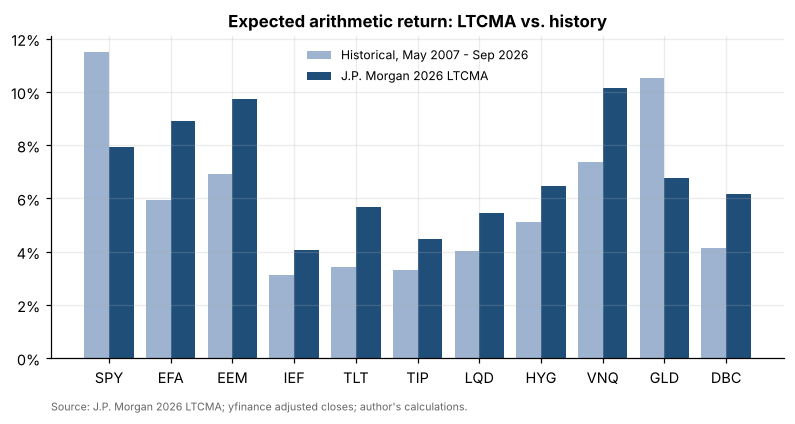

In [14]:
fig, ax = plt.subplots(figsize=(8.6, 3.8))
x = np.arange(len(TICK))
ax.bar(x - 0.2, hist["Hist. ann. return (arith.)"], 0.4, label="Historical, May 2007 - Sep 2026", color="#9DB3CF")
ax.bar(x + 0.2, hist["LTCMA arith."], 0.4, label="J.P. Morgan 2026 LTCMA", color=PALETTE[0])
ax.set_xticks(x, TICK); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Expected arithmetic return: LTCMA vs. history"); ax.legend(fontsize=8)
source(ax, "Source: J.P. Morgan 2026 LTCMA; yfinance adjusted closes; author's calculations.")
fig.savefig(FIG / "fig_ltcma_vs_history.png"); plt.show()

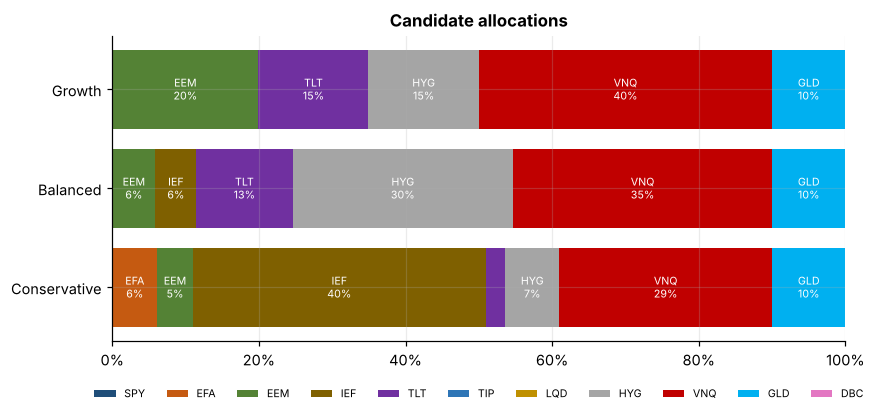

In [15]:
fig, ax = plt.subplots(figsize=(8.6, 3.6))
bottom = np.zeros(len(W.columns))
for i, t in enumerate(TICK):
    ax.barh(W.columns, W.loc[t], left=bottom, color=PALETTE[i], label=t)
    for j, v in enumerate(W.loc[t]):
        if v >= 0.04:
            ax.text(bottom[j] + v / 2, j, f"{t}\n{v:.0%}", ha="center", va="center", fontsize=7, color="white")
    bottom += W.loc[t].values
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Candidate allocations"); ax.legend(ncol=11, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.savefig(FIG / "fig_candidates.png"); plt.show()

## Save

In [16]:
W.to_csv(DATA / "candidate_weights.csv")
pd.concat([P, MC], axis=1).to_csv(DATA / "candidate_stats.csv")
front.to_csv(DATA / "frontier.csv")
SENS.to_csv(DATA / "sensitivity_reit_assumption.csv")
bands.to_csv(DATA / "policy_bands.csv")
hist.to_csv(DATA / "ltcma_vs_history.csv"); corr_cmp.to_csv(DATA / "corr_ltcma_vs_history.csv")
for k in W:
    pd.DataFrame({"median": np.median(SPEND[k], 0), "p10": np.percentile(SPEND[k], 10, 0),
                  "p90": np.percentile(SPEND[k], 90, 0)}, index=range(1, 21)).to_csv(DATA / f"real_spending_{k.lower()}.csv")
POLICY.rename("weight").to_csv(DATA / "final_policy_weights.csv")
pd.Series({**pol_stats, **pol_mc}).to_csv(DATA / "final_policy_stats.csv")
json.dump({"chosen": CHOSEN, "eligible": list(eligible), "band_events": len(events), "band_hard_events": len(events_hard), "band_hard_tol_events": len(events_hard_tol), "n_months": len(R),
           "band_event_dates": [str(d.date()) for d in events], "hist_chosen": hs,
           "min_vol": float(np.sqrt(w_min @ S @ w_min)), "min_vol_ret": float(w_min @ mu),
           "max_ret": float(w_max @ mu), "max_ret_vol": float(np.sqrt(w_max @ S @ w_max)),
           "inflation": float(infl["Compound 2026"]), "objective": float(infl["Compound 2026"] + 0.049)},
          open(DATA / "meta.json", "w"), indent=2, default=float)